In [2]:
import pystac_client
import planetary_computer
import rasterio
from rasterio.windows import Window
from rasterio.warp import Resampling, calculate_default_transform, reproject
import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

In [3]:
aoi_gdf=gpd.read_file("..\data\kolkata_aoi.gpkg")
print(f"AOI bounds: {aoi_gdf.total_bounds}")
print(f"AOI CRS: {aoi_gdf.crs}")
catalog=pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1")

AOI bounds: [88.25 22.5  88.45 22.7 ]
AOI CRS: EPSG:4326


In [4]:
import utils
from utils import read_band

In [5]:
from rasterio.warp import reproject
from rasterio.enums import Resampling

def resample_band_to_10m(band_20m, profile_20m, profile_10m):
    output = np.empty(
        (profile_10m["height"], profile_10m["width"]),
        dtype=np.float32
    )
    reproject(
        source=band_20m,
        destination=output,
        src_transform=profile_20m["transform"],
        src_crs=profile_20m["crs"],
        dst_transform=profile_10m["transform"],
        dst_crs=profile_10m["crs"],
        resampling=Resampling.nearest
    )
    return output
def calculate_ndvi(band_08, band_04):
    
    # NDVI = (NIR - RED) / (NIR + RED)  . Both bands expected at 10 m resolution.
    numerator = band_08.astype(float) - band_04.astype(float)
    denominator = band_08.astype(float) + band_04.astype(float)
    ndvi = np.divide(numerator, denominator, where=denominator != 0, out=np.full_like(numerator, np.nan))
    return ndvi
def calculate_ndwi(band_03, band_08):
    # NDWI = (GREEN - NIR) / (GREEN + NIR).  Both bands expected at 10 m resolution.
    numerator = band_03.astype(float) - band_08.astype(float)
    denominator = band_03.astype(float) + band_08.astype(float)
    ndwi = np.divide(numerator, denominator, where=denominator != 0, out=np.full_like(numerator, np.nan))
    return ndwi
def calculate_ndbi(band_11, band_08):
    # NDBI=(SWIR-NIR)/(SWIR+NIR). Band 11 resampled to 10 m; Band 08 native 10 m.
    numerator = band_11.astype(float) - band_08.astype(float)
    denominator = band_11.astype(float) + band_08.astype(float)
    ndbi = np.divide(numerator, denominator, where=denominator != 0, out=np.full_like(numerator, np.nan))
    return ndbi
print("Resampled and index functions defined")


Resampled and index functions defined


In [6]:
# Search for Sentinel-2 scenes over Kolkata in 2026
search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=aoi_gdf.total_bounds,
    datetime="2026-01-01/2026-09-04",
    query={"eo:cloud_cover": {"lt": 30}}
)

items = list(search.get_items())

print(f"Found {len(items)} scenes")

if len(items) > 0:
    # Sort using STAC item datetime
    items = sorted(items, key=lambda x: x.datetime, reverse=True)

    item = items[0]

    print(f"Selected scene: {item.datetime.date()}")
    print(f"Cloud cover: {item.properties.get('eo:cloud_cover', 'N/A')}%")
else:
    print("No scenes found. Try increasing the cloud threshold.")

Found 46 scenes
Selected scene: 2026-06-09
Cloud cover: 11.435559%


In [7]:
item=planetary_computer.sign(item)
band_04, prof_04=read_band(item, "B04", aoi_gdf)  # Red, 10 m
band_08, prof_08=read_band(item, "B08", aoi_gdf)  # NIR, 10 m
band_03, prof_03=read_band(item, "B03", aoi_gdf)  # Green, 10 m
band_11, prof_11=read_band(item, "B11", aoi_gdf)  # SWIR, 20 m
print("Band shapes:")
print(f"B04: {band_04.shape}")
print(f"B08: {band_08.shape}")
print(f"B03: {band_03.shape}")
print(f"B11: {band_11.shape}")
band_11_10m=resample_band_to_10m(band_11, prof_11, prof_04)
print(f"B11 after resampling: {band_11_10m.shape}")
ndvi=calculate_ndvi(band_08, band_04)
ndwi=calculate_ndwi(band_03, band_08)
ndbi=calculate_ndbi(band_11_10m, band_08)
print("\nIndex statistics:")
print(f"NDVI: min={np.nanmin(ndvi):.2f}, max={np.nanmax(ndvi):.2f}, mean={np.nanmean(ndvi):.2f}")
print(f"NDWI: min={np.nanmin(ndwi):.2f}, max={np.nanmax(ndwi):.2f}, mean={np.nanmean(ndwi):.2f}")
print(f"NDBI: min={np.nanmin(ndbi):.2f}, max={np.nanmax(ndbi):.2f}, mean={np.nanmean(ndbi):.2f}")

Band shapes:
B04: (2080, 2076)
B08: (2080, 2076)
B03: (2080, 2076)
B11: (1040, 1038)
B11 after resampling: (2080, 2076)

Index statistics:
NDVI: min=-0.55, max=0.78, mean=0.20
NDWI: min=-0.68, max=0.64, mean=-0.19
NDBI: min=-0.76, max=0.69, mean=-0.04


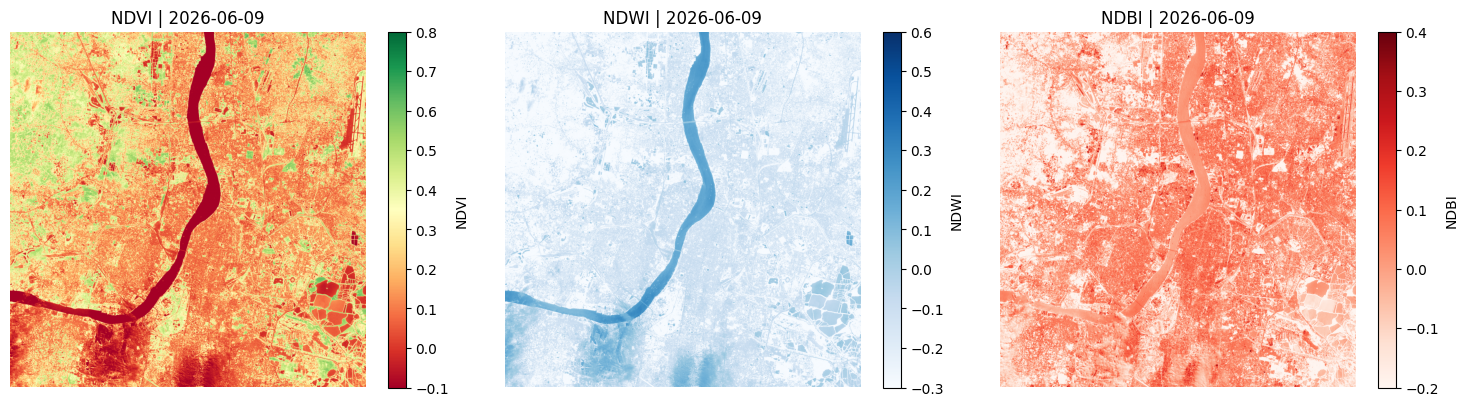

✓ Single-date NDVI, NDWI and NDBI maps created


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# NDVI
im0 = axes[0].imshow(
    ndvi,
    cmap="RdYlGn",
    vmin=-0.1,
    vmax=0.8
)
axes[0].set_title(f"NDVI | {item.datetime.date()}")
axes[0].axis("off")
plt.colorbar(im0, ax=axes[0], label="NDVI")

# NDWI
im1 = axes[1].imshow(
    ndwi,
    cmap="Blues",
    vmin=-0.3,
    vmax=0.6
)
axes[1].set_title(f"NDWI | {item.datetime.date()}")
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], label="NDWI")

# NDBI
im2 = axes[2].imshow(
    ndbi,
    cmap="Reds",
    vmin=-0.2,
    vmax=0.4
)
axes[2].set_title(f"NDBI | {item.datetime.date()}")
axes[2].axis("off")
plt.colorbar(im2, ax=axes[2], label="NDBI")

plt.tight_layout()
plt.show()

print("✓ Single-date NDVI, NDWI and NDBI maps created")

In [9]:
# Query Sentinel-2 scenes across 2026
search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=aoi_gdf.total_bounds,
    datetime="2026-01-01/2026-09-04",
    query={"eo:cloud_cover": {"lt": 30}})
items_all = list(search.get_items())
print(f"Total available scenes: {len(items_all)}")
if len(items_all) >= 3:
    # Sort chronologically
    items_all = sorted(items_all, key=lambda x: x.datetime)
    # Select early, middle and late observations
    selected_items = [
        items_all[0],
        items_all[len(items_all) // 2],
        items_all[-1]
    ]
    print("\nSelected scenes:")
    for i, it in enumerate(selected_items):
        print(
            f"  {i}: {it.datetime.date()} "
            f"(cloud: {it.properties.get('eo:cloud_cover', np.nan):.1f}%)"
        )
else:
    print("Fewer than 3 scenes found. Increase the cloud threshold or date range.")

Total available scenes: 46

Selected scenes:
  0: 2026-01-03 (cloud: 0.2%)
  1: 2026-02-12 (cloud: 0.0%)
  2: 2026-06-09 (cloud: 11.4%)


In [13]:
from rasterio.warp import reproject
from rasterio.enums import Resampling

def align_to_reference(array, source_profile, reference_profile):
    output = np.empty(
        (
            reference_profile["height"],
            reference_profile["width"]
        ),
        dtype=np.float32
    )

    reproject(
        source=array,
        destination=output,
        src_transform=source_profile["transform"],
        src_crs=source_profile["crs"],
        dst_transform=reference_profile["transform"],
        dst_crs=reference_profile["crs"],
        resampling=Resampling.nearest
    )

    return output

In [14]:
# Calculate indices for the selected dates
time_series = []

# First observation defines the common 10 m spatial grid
first_item = planetary_computer.sign(selected_items[0])
_, reference_profile = read_band(
    first_item, "B04", aoi_gdf
)

for i, item in enumerate(selected_items):

    item = planetary_computer.sign(item)
    acq_date = item.datetime

    # Read bands
    b04, prof_04 = read_band(item, "B04", aoi_gdf)
    b08, prof_08 = read_band(item, "B08", aoi_gdf)
    b03, prof_03 = read_band(item, "B03", aoi_gdf)
    b11, prof_11 = read_band(item, "B11", aoi_gdf)

    # Align all bands to the common 10 m reference grid
    b04 = align_to_reference(b04, prof_04, reference_profile)
    b08 = align_to_reference(b08, prof_08, reference_profile)
    b03 = align_to_reference(b03, prof_03, reference_profile)
    b11 = align_to_reference(b11, prof_11, reference_profile)

    # Calculate indices
    ndvi_t = calculate_ndvi(b08, b04)
    ndwi_t = calculate_ndwi(b03, b08)
    ndbi_t = calculate_ndbi(b11, b08)

    time_series.append({
        "date": acq_date,
        "ndvi": ndvi_t,
        "ndwi": ndwi_t,
        "ndbi": ndbi_t,
        "profile": reference_profile
    })

    print(
        f"[{i}] {acq_date.date()}: "
        f"NDVI: {ndvi_t.shape} "
        f"NDWI: {ndwi_t.shape} "
        f"NDBI: {ndbi_t.shape}"
    )

time_series = sorted(
    time_series,
    key=lambda x: x["date"]
)

print(f"\n✓ Computed indices for {len(time_series)} dates")

[0] 2026-01-03: NDVI: (2080, 2076) NDWI: (2080, 2076) NDBI: (2080, 2076)
[1] 2026-02-12: NDVI: (2080, 2076) NDWI: (2080, 2076) NDBI: (2080, 2076)
[2] 2026-06-09: NDVI: (2080, 2076) NDWI: (2080, 2076) NDBI: (2080, 2076)

✓ Computed indices for 3 dates


NDVI stack shape: (3, 2080, 2076)
NDVI median range: -0.228 to 0.612


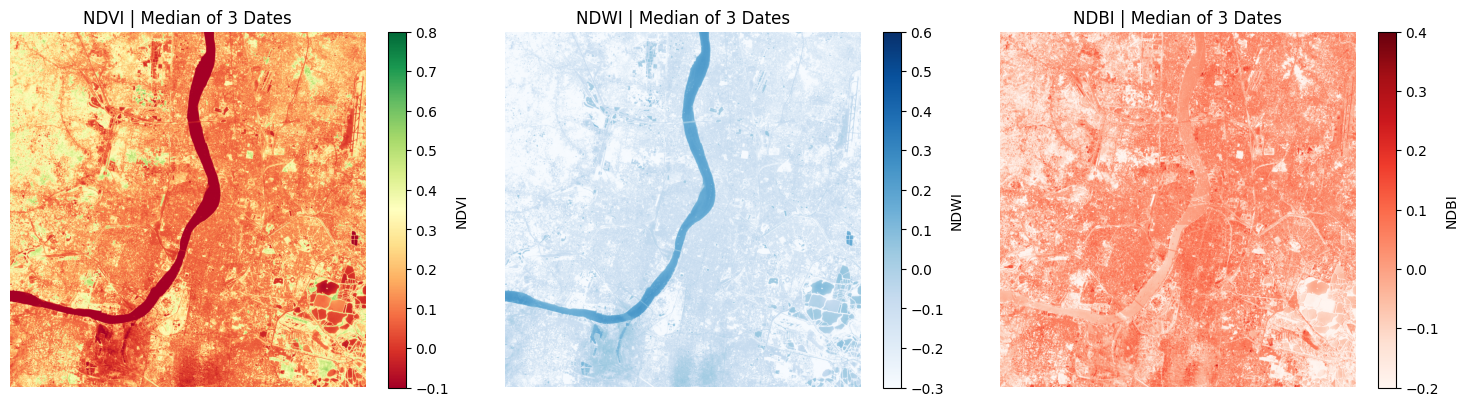

Temporal median composites created


In [15]:
ndvi_stack=np.array([ts["ndvi"] for ts in time_series])
ndwi_stack=np.array([ts["ndwi"] for ts in time_series])
ndbi_stack=np.array([ts["ndbi"] for ts in time_series])
print(f"NDVI stack shape: {ndvi_stack.shape}")
ndvi_median=np.nanmedian(ndvi_stack, axis=0)
ndwi_median=np.nanmedian(ndwi_stack, axis=0)
ndbi_median=np.nanmedian(ndbi_stack, axis=0)
print(f"NDVI median range: "
      f"{np.nanmin(ndvi_median):.3f} to {np.nanmax(ndvi_median):.3f}")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
im0=axes[0].imshow(ndvi_median, cmap="RdYlGn", vmin=-0.1, vmax=0.8)
axes[0].set_title("NDVI | Median of 3 Dates")
axes[0].axis("off")
plt.colorbar(im0, ax=axes[0], label="NDVI")
im1=axes[1].imshow(ndwi_median, cmap="Blues", vmin=-0.3, vmax=0.6)
axes[1].set_title("NDWI | Median of 3 Dates")
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], label="NDWI")
im2=axes[2].imshow(ndbi_median, cmap="Reds", vmin=-0.2, vmax=0.4)
axes[2].set_title("NDBI | Median of 3 Dates")
axes[2].axis("off")
plt.colorbar(im2, ax=axes[2], label="NDBI")
plt.tight_layout()
plt.show()
print("Temporal median composites created")

In [19]:
H,W=ndvi_stack.shape[1],ndvi_stack.shape[2]
T=len(time_series)
data_cube={
    "ndvi": ndvi_stack,
    "ndwi": ndwi_stack,
    "ndbi": ndbi_stack,
    "dates": [ts["date"] for ts in time_series],
    "profile": time_series[0]["profile"]
}
print("Data cube summary:")
print(f"\nTime steps: {T}")
print(f"\nSpatial dimensions: {H}×{W} pixels")
print(
    f"Temporal coverage: "
    f"{data_cube['dates'][0].date()} to "
    f"{data_cube['dates'][-1].date()}\n")
print(f"NDVI cube shape: {data_cube['ndvi'].shape}")
print(f"NDWI cube shape: {data_cube['ndwi'].shape}")
print(f"NDBI cube shape: {data_cube['ndbi'].shape}")

Data cube summary:

Time steps: 3

Spatial dimensions: 2080×2076 pixels
Temporal coverage: 2026-01-03 to 2026-06-09

NDVI cube shape: (3, 2080, 2076)
NDWI cube shape: (3, 2080, 2076)
NDBI cube shape: (3, 2080, 2076)


In [21]:
ndvi_t0=data_cube["ndvi"][0]  #first observation
ndvi_t_end=data_cube["ndvi"][-1]   #last observation
ndvi_change=ndvi_t_end-ndvi_t0
print("NDVI change statistics:")
print(f"Minimum:{np.nanmin(ndvi_change):.3f}")
print(f"Maximum:{np.nanmax(ndvi_change):.3f}")
print(f"Mean:{np.nanmean(ndvi_change):.3f}")
print(f"Standard deviation:{np.nanstd(ndvi_change):.3f}")
greening_mask=ndvi_change>0.1
browning_mask=ndvi_change<-0.1
valid_pixels=np.sum(np.isfinite(ndvi_change))
print("\nThresholded changes:")
print(
    f"  NDVI increase > 0.1: "
    f"{greening_mask.sum()} pixels "
    f"({100*greening_mask.sum()/valid_pixels:.1f}%)"
)
print(
    f"  NDVI decrease<(-0.1): "
    f"{browning_mask.sum()} pixels "
    f"({100*browning_mask.sum()/valid_pixels:.1f}%)"
)

NDVI change statistics:
Minimum:-0.735
Maximum:0.716
Mean:0.056
Standard deviation:0.093

Thresholded changes:
  NDVI increase > 0.1: 1230283 pixels (28.5%)
  NDVI decrease<(-0.1): 159086 pixels (3.7%)


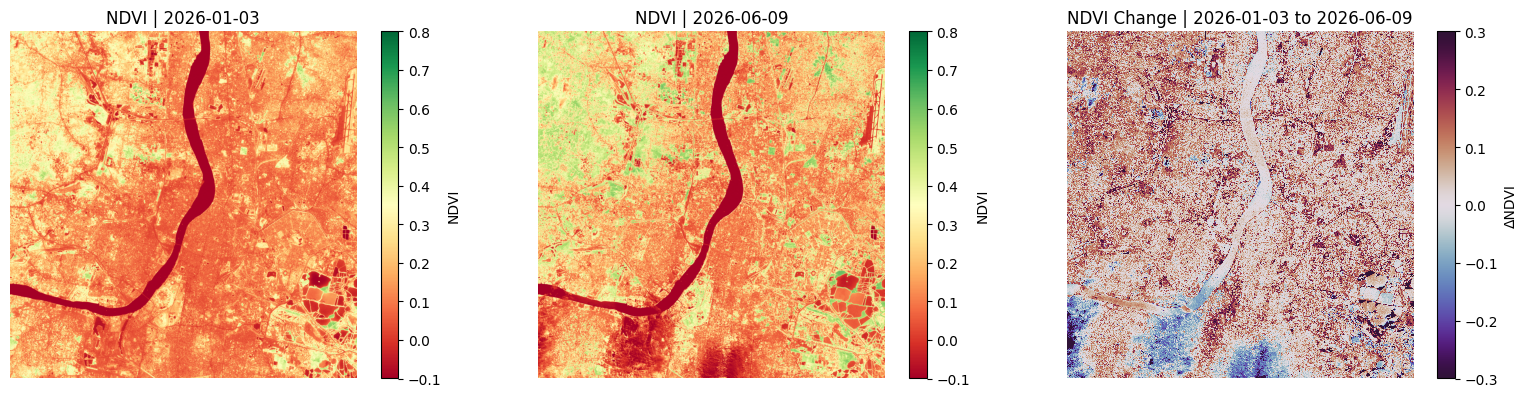

NDVI change map created: 2026-01-03 to 2026-06-09


In [25]:
date_t0=data_cube["dates"][0].date()
date_t_end=data_cube["dates"][-1].date()
fig, axes=plt.subplots(1, 3, figsize=(16, 4))
# First observation
im0=axes[0].imshow(
    ndvi_t0,
    cmap="RdYlGn",
    vmin=-0.1,
    vmax=0.8
)
axes[0].set_title(f"NDVI | {date_t0}")
axes[0].axis("off")
plt.colorbar(im0,ax=axes[0],label="NDVI")
im1=axes[1].imshow(
    ndvi_t_end,
    cmap="RdYlGn",
    vmin=-0.1,
    vmax=0.8
)
axes[1].set_title(f"NDVI | {date_t_end}")
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], label="NDVI")
im2 = axes[2].imshow(
    ndvi_change,
    cmap="twilight_shifted",
    vmin=-0.3,
    vmax=0.3,
    interpolation="nearest"
)
axes[2].set_title(
    f"NDVI Change | {date_t0} to {date_t_end}"
)
axes[2].axis("off")
plt.colorbar(im2, ax=axes[2], label="ΔNDVI")
plt.tight_layout()
plt.show()
print(f"NDVI change map created: {date_t0} to {date_t_end}")